# N2 / STO-3G, frozen core: vDBF PES and exact DBF convergence

Two results from the qualifying-exam runs, collected here as the starting point for the excited-state work (`code/vdbf_excited_states.md`).

1. **PES.** vDBF at coefficient cutoffs $10^{-5}$ and $10^{-6}$ against UHF, UCCSD, UCCSD(T) and FCI. UNO start (closed-shell UHF natural orbitals), flow on $H + 0.05\,S^2$, frozen UNO 1s core (16 qubits). Each vDBF point is the variance-extrapolated $E_0$ from the adaptive tail fit in `extrapolate.py`.
2. **Exact DBF.** The untruncated flow (`frozen_core/sv_dbf.jl`, dense state vector on the parity sector reachable from $|0\rangle$) at $R = 2.3$ Å for five starts. This is the truncation-free reference for what the greedy flow itself can reach.

**Data is not in git.** The notebook reads it from `frozen_core/` here if present, otherwise from the qual_exam checkout next to this one, or from `$N2_DATA`. To regenerate (from `code/n2_pes/frozen_core/`):

```
python make_uno_integrals.py                                  # data_unocore/R_*/  integrals + metadata (FCI)
julia --project=.. build_fc_hamiltonians.jl ...               # hamiltonian_uno.jld2, s2_uno.jld2 (see build_s2.jl)
julia --project=.. ../run_dbf_pes.jl ...                      # dbf_uno_s2pen0.05[_c1e-6].json; see run_uno_pes_local.sh
python fc_cc.py                                               # results/fc_cc.csv (UHF, UCCSD, UCCSD(T))
julia -t 8 --project=../../integrals sv_dbf.jl data_unocore/R_2.30 uno uno_2.30_onebody --rank onebody --s2-penalty 0.05
```
See `code/n2_pes/README.md` and the headers of each script for the exact arguments.

In [1]:
import csv, json, os, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()                      # code/n2_pes
sys.path.insert(0, str(HERE))
from extrapolate import MIN_FIT_POINTS, select_adaptive_tail

def _has_data(p):
    return p is not None and (p / "data_unocore").is_dir() and (p / "sv_results").is_dir()

candidates = [Path(os.environ["N2_DATA"]) if "N2_DATA" in os.environ else None,
              HERE / "frozen_core",
              HERE.parents[3] / "qual_exam" / "DBF.jl" / "code" / "n2_pes" / "frozen_core"]
FC = next(p for p in candidates if _has_data(p))
print("data from", os.path.relpath(FC, HERE))

MHA = 1e3
plt.rcParams.update({"font.size": 9, "axes.linewidth": 1.0, "legend.fontsize": 8,
                     "figure.dpi": 130, "axes.grid": True, "grid.color": "#e5e5e5"})

data from ../../../../qual_exam/DBF.jl/code/n2_pes/frozen_core


## 1. PES at coefficient cutoffs $10^{-5}$ and $10^{-6}$

vDBF energies and variances are the corrected ones the run reports ($E - \text{err}$, $\mathrm{Var} - \text{var err}$). The error bar is the half-difference between the linear and quadratic tail fits. The grey band is $\pm 1.6$ mHa.

In [2]:
STEMS = {"1e-5": "dbf_uno_s2pen0.05", "1e-6": "dbf_uno_s2pen0.05_c1e-6"}   # cutoff -> run file stem

points = sorted(d for d in os.listdir(FC / "data_unocore") if d.startswith("R_")
                and all((FC / "data_unocore" / d / f"{s}.json").exists() for s in STEMS.values()))
R, fci, nrot = [], [], {c: [] for c in STEMS}
e0 = {c: [] for c in STEMS}
e0u = {c: [] for c in STEMS}
for d in points:
    meta = json.load(open(FC / "data_unocore" / d / "metadata.json"))
    R.append(meta["R_angstrom"])
    fci.append(meta["constant"] + meta["E_FCI_with_mu"])
    for c, stem in STEMS.items():
        run = json.load(open(FC / "data_unocore" / d / f"{stem}.json"))
        h = run["history"]
        E = (np.array(h["energies_per_grad"]) - np.array(h["accumulated_error_per_grad"]))[1:]
        V = (np.array(h["variance_per_grad"]) - np.array(h["accumulated_var_error_per_grad"]))[1:]
        best, _ = select_adaptive_tail(V, E, MIN_FIT_POINTS)
        e0[c].append(best["E0_average"])
        e0u[c].append(best["fit_half_difference"])
        nrot[c].append(run["n_rotations"])
R, fci = np.array(R), np.array(fci)
e0 = {c: np.array(v) for c, v in e0.items()}
e0u = {c: np.array(v) for c, v in e0u.items()}

cc = {round(float(r["R"]), 2): r for r in csv.DictReader(open(FC / "results" / "fc_cc.csv"))}
col = lambda k: np.array([float(cc[round(r, 2)][k]) for r in R])
methods = [("UHF", col("E_UHF"), "C0", "-", "o"),
           ("UCCSD", col("E_UCCSD"), "C1", "-", "s"),
           ("UCCSD(T)", col("E_UCCSD_T"), "C2", "--", "^")]
VDBF = {"1e-5": (r"vDBF, $10^{-5}$", "C4", "D"), "1e-6": (r"vDBF, $10^{-6}$", "C3", "o")}
print(f"{len(R)} geometries, R = {R.min():.2f} .. {R.max():.2f} A")

23 geometries, R = 0.80 .. 3.00 A


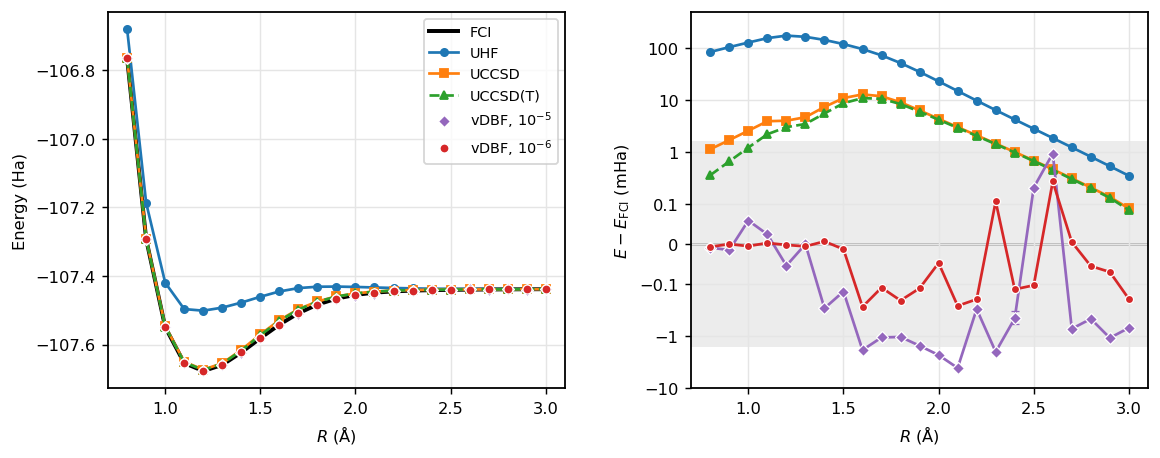

In [3]:
fig, (ap, ae) = plt.subplots(1, 2, figsize=(9, 3.6))

ap.plot(R, fci, "-", color="black", lw=2.2, label="FCI", zorder=2)
for lab, E, c, ls, m in methods:
    ap.plot(R, E, ls=ls, marker=m, color=c, lw=1.5, ms=4, label=lab, zorder=3)
for c, (lab, colr, m) in VDBF.items():
    ap.plot(R, e0[c], m, color=colr, ms=5, mec="white", mew=0.7, label=lab, zorder=5)
ap.set_ylabel("Energy (Ha)")
ap.legend(loc="upper right")

ae.axhspan(-1.6, 1.6, color="#ececec", lw=0, zorder=0)
ae.axhline(0, color="black", lw=0.8, zorder=1)
for lab, E, c, ls, m in methods:
    ae.plot(R, (E - fci) * MHA, ls=ls, marker=m, color=c, lw=1.5, ms=4, label=lab, zorder=3)
for c, (lab, colr, m) in VDBF.items():
    ae.errorbar(R, (e0[c] - fci) * MHA, yerr=e0u[c] * MHA, fmt=f"{m}-", color=colr, lw=1.5, ms=4.5,
                mec="white", mew=0.7, capsize=2, label=lab, zorder=5)
ae.set_yscale("symlog", linthresh=0.1, linscale=0.7)
ae.set_ylim(-10, 500)
ae.set_yticks([-10, -1, -0.1, 0, 0.1, 1, 10, 100])
ae.set_yticklabels(["−10", "−1", "−0.1", "0", "0.1", "1", "10", "100"])
ae.set_ylabel(r"$E - E_{\mathrm{FCI}}$ (mHa)")
for a in (ap, ae):
    a.set_xlabel("$R$ (Å)")
    a.set_xlim(0.7, 3.1)
fig.tight_layout(w_pad=3)
plt.show()

In [4]:
print(f"{'R':>5} " + " ".join(f"{m[0]:>9}" for m in methods)
      + "".join(f" {'E0 ' + c:>9}" for c in STEMS) + "".join(f" {'rots ' + c:>11}" for c in STEMS) + "   (mHa vs FCI)")
for i, r in enumerate(R):
    print(f"{r:5.2f} " + " ".join(f"{(m[1][i] - fci[i]) * MHA:+9.3f}" for m in methods)
          + "".join(f" {(e0[c][i] - fci[i]) * MHA:+9.3f}" for c in STEMS)
          + "".join(f" {nrot[c][i]:11d}" for c in STEMS))
for c in STEMS:
    err = np.abs(e0[c] - fci) * MHA
    print(f"cutoff {c}: max |E0 - FCI| = {err.max():.3f} mHa at R = {R[err.argmax()]:.2f}, "
          f"{(err < 1.6).sum()}/{len(R)} points within 1.6 mHa")

    R       UHF     UCCSD  UCCSD(T)   E0 1e-5   E0 1e-6   rots 1e-5   rots 1e-6   (mHa vs FCI)
 0.80   +85.132    +1.131    +0.358    -0.009    -0.007        3078        2976
 0.90  +105.522    +1.700    +0.659    -0.015    +0.000        3700        3396
 1.00  +129.434    +2.576    +1.218    +0.059    -0.005        5500        4682
 1.10  +157.327    +3.924    +2.202    +0.024    +0.003        5184        4350
 1.20  +175.881    +4.015    +3.011    -0.053    -0.002        6146        4950
 1.30  +166.825    +4.694    +3.475    -0.000    -0.005       10000        8100
 1.40  +145.289    +7.401    +5.538    -0.288    +0.007       10000       10000
 1.50  +120.809   +10.970    +8.740    -0.137    -0.013       10000       10000
 1.60   +96.767   +12.916   +10.951    -1.840    -0.270       10000       10000
 1.70   +73.253   +11.907   +10.640    -1.053    -0.115       10000       10000
 1.80   +51.982    +9.090    +8.410    -1.028    -0.204       10000       10000
 1.90   +35.130    +6.356

## 2. Exact DBF convergence, $R = 2.3$ Å

`sv_dbf.jl` keeps the full dressing $W = U_1 \cdots U_K$ as a dense orthogonal matrix, so energy, variance, fidelity with the exact ground state and $\langle S^2\rangle$ are exact at every macro-iteration (50 rotations each, one-body ranking $|x|\,O_{x0}^2$). Nothing is truncated: whatever error is left is the greedy flow's, not Pauli propagation's.

Starts: UHF determinant in the LNO basis on $H$, on $H + 0.05\,S^2$, and its singlet projection; the closed-shell UNO determinant on $H$ and on $H + 0.05\,S^2$. Energies and variances are always of $H$. Each run is measured from its own FCI (UNO and LNO freeze different 1s orbitals; the FCIs differ by about 3 µHa).

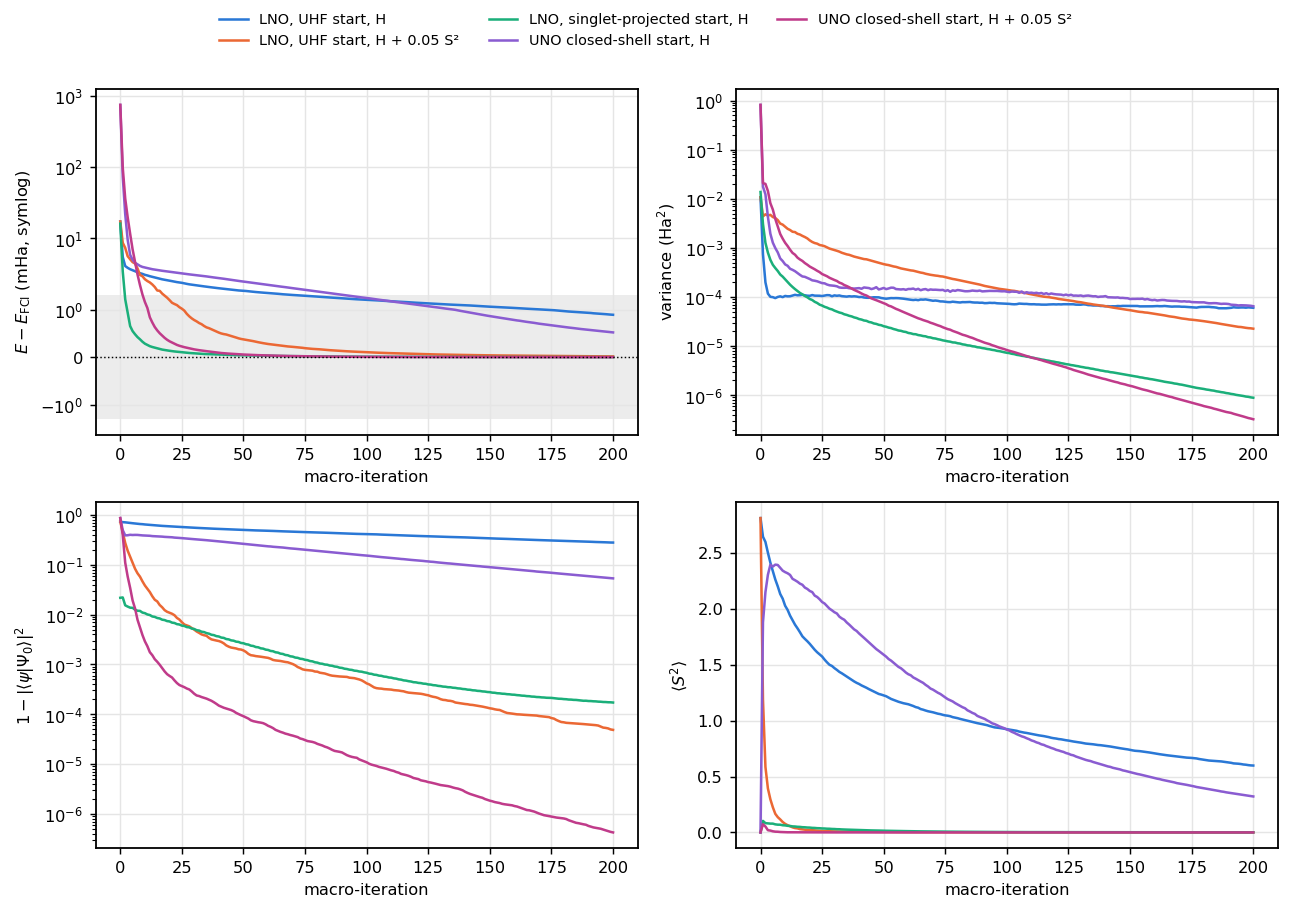

In [5]:
EXACT = [("LNO, UHF start, H",                "#2a78d6", "lno_2.30_onebody"),
         ("LNO, UHF start, H + 0.05 S²",    "#eb6834", "lno_2.30_onebody_s2pen0.05"),
         ("LNO, singlet-projected start, H",    "#1baf7a", "lno_2.30_onebody_singlet"),
         ("UNO closed-shell start, H",          "#8a5cd1", "uno_2.30_onebody"),
         ("UNO closed-shell start, H + 0.05 S²", "#c03b8a", "uno_2.30_onebody_s2pen0.05")]
sv = {key: json.load(open(FC / "sv_results" / f"{key}.json")) for _, _, key in EXACT}

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for lab, colr, key in EXACT:
    d = sv[key]; h = d["history"]
    it = np.arange(len(h["E"]))
    ax[0, 0].plot(it, (np.array(h["E"]) - d["E_FCI"]) * MHA, color=colr, lw=1.4, label=lab)
    ax[0, 1].plot(it, h["var"], color=colr, lw=1.4)
    ax[1, 0].plot(it, np.maximum(1 - np.array(h["fidelity"]), 1e-16), color=colr, lw=1.4)
    ax[1, 1].plot(it, h["S2"], color=colr, lw=1.4)
ax[0, 0].set_yscale("symlog", linthresh=1.0, linscale=0.6); ax[0, 0].axhline(0, color="k", lw=0.8, ls=":")
ax[0, 0].axhspan(-1.6, 1.6, color="#ececec", lw=0, zorder=0)
ax[0, 0].set_ylabel(r"$E - E_{\mathrm{FCI}}$ (mHa, symlog)")
ax[0, 1].set_yscale("log"); ax[0, 1].set_ylabel(r"variance (Ha$^2$)")
ax[1, 0].set_yscale("log"); ax[1, 0].set_ylabel(r"$1 - |\langle\psi|\Psi_0\rangle|^2$")
ax[1, 1].set_ylabel(r"$\langle S^2 \rangle$")
for a in ax.flat:
    a.set_xlabel("macro-iteration")
fig.legend(*ax[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

Energy against variance, with the same adaptive tail fit used for vDBF. Left: whole trajectory. Right: the points in the selected tail, its linear (dashed) and quadratic (solid) fits, and $E_0$ = their average intercept, with the half-difference as error bar (marker on the axis). The two runs that end far from FCI (UHF and UNO starts on bare $H$) are still spin-contaminated (lower right of the previous figure), so their tails are not yet in the linear regime and $E_0$ there is unreliable.

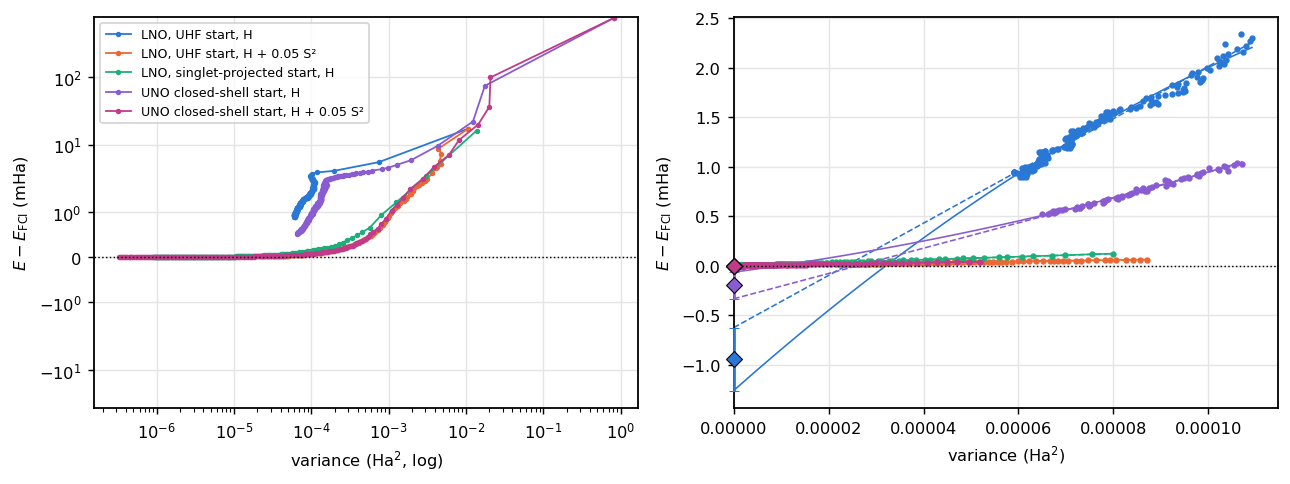

start                                  iters     E-FCI    E0-FCI        Var        1-F     <S2>   (mHa, Ha^2)
LNO, UHF start, H                        200    +0.892    -0.943   6.04e-05   2.81e-01   0.5981
LNO, UHF start, H + 0.05 S²              200    +0.016    +0.000   2.26e-05   4.86e-05   0.0001
LNO, singlet-projected start, H          200    +0.001    -0.001   8.90e-07   1.72e-04   0.0005
UNO closed-shell start, H                200    +0.521    -0.200   6.49e-05   5.36e-02   0.3216
UNO closed-shell start, H + 0.05 S²      200    +0.000    -0.000   3.25e-07   4.23e-07   0.0000

lowest exact gaps above the ground state (mHa): 8.99, 120.02, 122.00, 122.00, 142.78


In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
rows = []
for lab, colr, key in EXACT:
    d = sv[key]; h = d["history"]
    E, V = np.array(h["E"]), np.array(h["var"])
    y = (E - d["E_FCI"]) * MHA
    a1.plot(V, y, "o-", color=colr, ms=2, lw=1.0, label=lab)
    best, _ = select_adaptive_tail(V[1:], E[1:], MIN_FIT_POINTS)
    k = best["num_take"]
    a2.plot(V[-k:], y[-k:], "o", color=colr, ms=2.5)
    xs = np.linspace(0, V[-k:].max(), 80)
    a2.plot(xs, np.polyval(np.polyfit(V[-k:], y[-k:], 1), xs), "--", color=colr, lw=0.9)
    a2.plot(xs, np.polyval(np.polyfit(V[-k:], y[-k:], 2), xs), "-", color=colr, lw=0.9)
    e0x = (best["E0_average"] - d["E_FCI"]) * MHA
    a2.errorbar(0, e0x, yerr=best["fit_half_difference"] * MHA, fmt="D", color=colr, ms=6,
                mec="k", mew=0.6, capsize=3, clip_on=False, zorder=5)
    rows.append((lab, len(E) - 1, y[-1], e0x, V[-1], 1 - h["fidelity"][-1], h["S2"][-1]))
a1.set_xscale("log"); a1.set_yscale("symlog", linthresh=1.0, linscale=0.6); a1.axhline(0, color="k", lw=0.8, ls=":")
a1.set_xlabel(r"variance (Ha$^2$, log)"); a1.set_ylabel(r"$E - E_{\mathrm{FCI}}$ (mHa)")
a2.axhline(0, color="k", lw=0.8, ls=":"); a2.set_xlim(left=0)
a2.set_xlabel(r"variance (Ha$^2$)"); a2.set_ylabel(r"$E - E_{\mathrm{FCI}}$ (mHa)")
a1.legend(fontsize=7)
fig.tight_layout()
plt.show()

print(f"{'start':<38} {'iters':>5} {'E-FCI':>9} {'E0-FCI':>9} {'Var':>10} {'1-F':>10} {'<S2>':>8}   (mHa, Ha^2)")
for r in rows:
    print(f"{r[0]:<38} {r[1]:5d} {r[2]:+9.3f} {r[3]:+9.3f} {r[4]:10.2e} {r[5]:10.2e} {r[6]:8.4f}")
print("\nlowest exact gaps above the ground state (mHa):",
      ", ".join(f"{g:.2f}" for g in sv["uno_2.30_onebody"]["gaps_mHa"]))

**Relevance for the excited-state plan.** The `gaps_mHa` printed above are the lowest excitation energies of the frozen-core sector from exact diagonalisation, a ready-made reference for Stage 1/2. The first gap at 2.3 Å is small (about 9 mHa), so a block that should hold S0 and the first excited state is in the near-degenerate regime where intruders (plan §6.2) matter. `sv_dbf.jl` already stores the full dressing $W$, so the block cost $C_S$, the block variance $V_S$ and the block matrix $M$ (plan §3.2, §3.5, §3.6) can be computed exactly on this system before touching the truncated code.